# Практическая работа №6. Классификация текстов

 
**Тема:** CountVectorizer, TF-IDF и Naive Bayes

**Цель:** научиться определять спам в SMS и сравнить два способа преобразования текста в числовые признаки.

## 1.Импорт библиотек

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Загрузка данных

In [2]:
paths = [
    Path("spam.csv"),
    Path("PR6/spam.csv")
]

dataset_path = next((p for p in paths if p.is_file()), None)

if dataset_path is None:
    raise FileNotFoundError("Файл spam.csv не найден")

df = pd.read_csv(dataset_path, encoding="latin-1")

df = df[["v1", "v2"]].rename(columns={
    "v1": "label",
    "v2": "text"
})

print("Размер датасета:", df.shape)
display(df.head())

print("\nКоличество сообщений по классам:")
print(df["label"].value_counts())

Размер датасета: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Количество сообщений по классам:
label
ham     4825
spam     747
Name: count, dtype: int64


## 3. Подготовка данных

In [3]:
df = df.dropna(subset=["text", "label"]).copy()

df["target"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df = df.dropna(subset=["target"])
df["target"] = df["target"].astype(int)

X = df["text"].astype(str)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (4457,)
Test: (1115,)


## 4. Первая модель

In [4]:
count_model = Pipeline([
    ("vectorizer", CountVectorizer()),
    ("classifier", MultinomialNB())
])

count_model.fit(X_train, y_train)

count_pred = count_model.predict(X_test)

count_accuracy = accuracy_score(y_test, count_pred)
count_f1 = f1_score(y_test, count_pred, zero_division=0)

print("CountVectorizer")
print("Accuracy:", round(count_accuracy, 4))
print("F1:", round(count_f1, 4))

print(
    "Количество признаков:",
    len(count_model.named_steps["vectorizer"].vocabulary_)
)

CountVectorizer
Accuracy: 0.9839
F1: 0.9379
Количество признаков: 7701


## 5. TF-IDF
TF-IDF + Naive Bayes

`TfidfVectorizer` учитывает не только частоту слова в сообщении, но и то, насколько часто это слово встречается во всём обучающем корпусе.

Обучаю вторую модель на том же Train/Test, чтобы сравнение было справедливым.

In [5]:
tfidf_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

tfidf_model.fit(X_train, y_train)

tfidf_pred = tfidf_model.predict(X_test)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)
tfidf_f1 = f1_score(y_test, tfidf_pred, zero_division=0)

print("TF-IDF")
print("Accuracy:", round(tfidf_accuracy, 4))
print("F1:", round(tfidf_f1, 4))

print(
    "Количество признаков:",
    len(tfidf_model.named_steps["vectorizer"].vocabulary_)
)

TF-IDF
Accuracy: 0.9605
F1: 0.8268
Количество признаков: 7701


6 — Таблица и график

,Модель,Accuracy,F1
0,CountVectorizer,0.9839,0.9379
1,TF-IDF,0.9605,0.8268


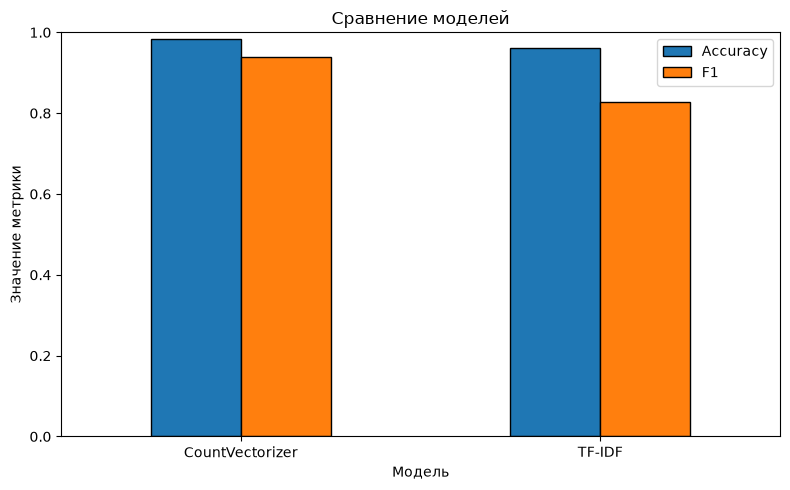

In [6]:
results = pd.DataFrame({
    "Модель": ["CountVectorizer", "TF-IDF"],
    "Accuracy": [count_accuracy, tfidf_accuracy],
    "F1": [count_f1, tfidf_f1]
})

display(results.round(4))

results.set_index("Модель")[["Accuracy", "F1"]].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    edgecolor="black"
)

plt.title("Сравнение моделей")
plt.ylabel("Значение метрики")
plt.xlabel("Модель")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Матрица ошибок

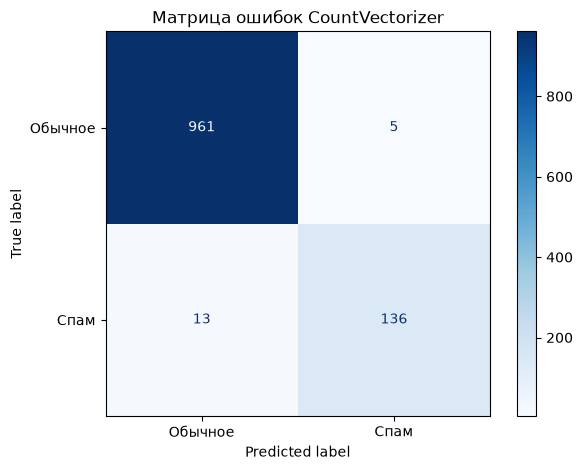

In [7]:
cm = confusion_matrix(y_test, count_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Обычное", "Спам"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Матрица ошибок CountVectorizer")
plt.tight_layout()
plt.show()

8 — Примеры ошибок

In [8]:
errors = pd.DataFrame({
    "text": X_test.to_numpy(),
    "true": y_test.to_numpy(),
    "predicted": count_pred
})

errors = errors[errors["true"] != errors["predicted"]]

print("Количество ошибок:", len(errors))
display(errors.head(5))

Количество ошибок: 18


,text,true,predicted
44,FreeMsg Hey there darling it's been 3 week's n...,1,0
99,Anytime...,0,1
187,Waiting for your call.,0,1
219,Sorry I missed your call let's talk when you h...,1,0
235,"Latest News! Police station toilet stolen, cop...",1,0


 Вывод

В этой работе я обучил две модели классификации SMS.

**Результаты:**

| Модель | Accuracy | F1 |
|---|---|---|
| CountVectorizer | [значение] | [значение] |
| TF-IDF | [значение] | [значение] |

По F1 лучше сработала модель **[название]**.

Я также проверил ошибочные предсказания. Возможные причины ошибок — необычные слова, сокращения и сообщения, которые похожи на обычный текст.

**Итог:** научился преобразовывать тексты в числовые признаки и классифицировать сообщения с помощью Naive Bayes.